# Evaluation _ Classification de sentiments de tweets
*Cours : CY Tech — NLP 2025/2026 (Groupe B)*  
*Auteur : JOUDI Haroun*  

## Imports

In [ ]:
from datasets import load_dataset
import re, string
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

import nltk
try:
    from nltk.corpus import stopwords
    _ = stopwords.words('english')
except LookupError:
    nltk.download('stopwords')
    from nltk.corpus import stopwords


## 1) Charger le dataset et afficher quelques exemples

In [ ]:
dataset = load_dataset("tweet_eval", "sentiment", split="train[:2000]")
print(dataset)

# Exemples
for i in range(3):
    print(f"Example {i+1}: label={dataset[i]['label']}, text={dataset[i]['text'][:200]}")

# Mapping: 0=negative, 1=neutral, 2=positive
id2label = {0:"negative", 1:"neutral", 2:"positive"}
label2id = {v:k for k,v in id2label.items()}


Dataset({
    features: ['text', 'label'],
    num_rows: 2000
})
Example 1: label=2, text="QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin"
Example 2: label=1, text="Ben Smith / Smith (concussion) remains out of the lineup Thursday, Curtis #NHL #SJ"
Example 3: label=1, text=Sorry bout the stream last night I crashed out but will be on tonight for sure. Then back to Minecraft in pc tomorrow night.


## 2) Nettoyage du texte (minuscules, ponctuation, stopwords)

In [ ]:
stop_en = set(stopwords.words('english'))
url_pat = re.compile(r'https?://\S+|www\.\S+')
mention_pat = re.compile(r'@[A-Za-z0-9_]+')
hashtag_pat = re.compile(r'#(\w+)')
punct_tbl = str.maketrans('', '', string.punctuation)

def clean_text(s: str) -> str:
    s = s.lower()
    s = url_pat.sub(' ', s)
    s = mention_pat.sub(' ', s)
    s = hashtag_pat.sub(r'\1', s)
    s = s.translate(punct_tbl)
    s = re.sub(r'\d+', ' ', s)      # supprime chiffres
    s = re.sub(r'\s+', ' ', s).strip()

    # stopwords
    tokens = [w for w in s.split() if w not in stop_en]
    return ' '.join(tokens)

texts = [clean_text(t) for t in dataset['text']]
y = np.array(dataset['label'])

print("Verification :\n")
print("Avant  :", dataset[0]['text'][:120])
print("Après  :", texts[0][:120])

Verification :

Avant  : "QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin"
Après  : qt original draft th book remus lupin survived battle hogwarts happybirthdayremuslupin


## 3) Représentation TF–IDF

In [ ]:
# Unigrams
vectorizer = TfidfVectorizer(ngram_range=(1,2), min_df=2, max_df=0.95)
X = vectorizer.fit_transform(texts)
X.shape


(2000, 2553)

In [ ]:
# Split entraînement/test (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train :", X_train.shape, "//  Test :", X_test.shape)


Train : (1600, 2553) //  Test : (400, 2553)


## 4) Entraîner un modèle (LogisticRegression ou SVM)

In [ ]:

# Régression Logistique
logreg = LogisticRegression(max_iter=1000, class_weight='balanced')
logreg.fit(X_train, y_train)

# SVM linéaire
svm = LinearSVC()
svm.fit(X_train, y_train)

print("OK")

OK


## 5) Évaluation (accuracy, precision, recall, F1, matrice de confusion)

Évaluation Logistic Regression
[LogReg] accuracy=0.515 | precision=0.478 | recall=0.484 | f1=0.480

Rapport par classe :
              precision    recall  f1-score   support

    negative       0.32      0.37      0.34        63
     neutral       0.56      0.54      0.55       180
    positive       0.56      0.54      0.55       157

    accuracy                           0.52       400
   macro avg       0.48      0.48      0.48       400
weighted avg       0.52      0.52      0.52       400



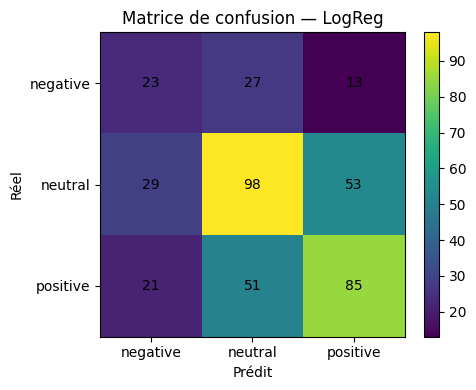


Évaluation SVM linéaire
[LinearSVC] accuracy=0.527 | precision=0.480 | recall=0.463 | f1=0.466

Rapport par classe :
              precision    recall  f1-score   support

    negative       0.34      0.22      0.27        63
     neutral       0.55      0.61      0.58       180
    positive       0.55      0.56      0.55       157

    accuracy                           0.53       400
   macro avg       0.48      0.46      0.47       400
weighted avg       0.52      0.53      0.52       400



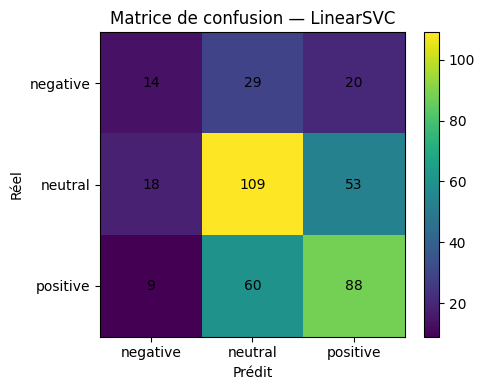

In [ ]:

def eval_model(model, X_te, y_te, name: str):
    y_pred = model.predict(X_te)
    acc = accuracy_score(y_te, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_te, y_pred, average='macro', zero_division=0)

    print(f"[{name}] accuracy={acc:.3f} | precision={p:.3f} | recall={r:.3f} | f1={f1:.3f}")
    print("\nRapport par classe :")
    print(classification_report(y_te, y_pred, target_names=[id2label[i] for i in range(3)]))

    # Matrice de confusion
    cm = confusion_matrix(y_te, y_pred, labels=[0,1,2])

    fig = plt.figure(figsize=(5,4))
    plt.imshow(cm, interpolation='nearest')
    plt.title(f"Matrice de confusion — {name}")
    plt.xticks([0,1,2], [id2label[i] for i in range(3)])
    plt.yticks([0,1,2], [id2label[i] for i in range(3)])
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, cm[i, j], ha='center', va='center')
    plt.xlabel("Prédit")
    plt.ylabel("Réel")
    plt.colorbar()
    plt.tight_layout()
    plt.show()
    return {"acc":acc, "p":p, "r":r, "f1":f1}

print("Évaluation Logistic Regression")
m_lr  = eval_model(logreg, X_test, y_test, "LogReg")

print("\nÉvaluation SVM linéaire")
m_svm = eval_model(svm,   X_test, y_test, "LinearSVC")


## 6) Commentaires


Les deux modèles sont autour de 0.52 en accuracy. Et pour le F1 macro, on a LogReg = 0.480 et SVM = 0.466.

On regarde le F1 macro pour comparer les trois classes de façon plus équitable que l’accuracy.

**Classe negative:**

 LogReg détecte un peu mieux (rappel **0.37**) alors que SVM en oublie pas mal (rappel **0.22**). On voit que beaucoup de négatifs sont prédits comme neutral.

**Classe neutral :**

SVM s’en sort mieux (rappel **0.61** contre **0.54** pour LogReg). C’est probablement ce qui lui donne une accuracy un peu plus haute.


**Classe positive:**

 Les deux modèles sont proches, avec précision et rappel autour de 0.55. Il y a des confusions entre neutral et positive dans les deux cas.

Pour améliorer simplement, On peut tester TF-IDF (1,2) pour capter des petites expressions, ajuster le paramètre C, et mieux traiter les négations et les emojis.



## 7) Conclusion
On garde Logistic Regression car il a le meilleur F1 macro. SVM a une accuracy légèrement plus élevée, mais ici On privilégie le F1 macro.

## Classification avec un modèle LLM local (zéro-shot) et comparaison
on envoie 50 tweets au modèle, il répond "negative / neutral / positive", puis on compare le F1 macro avec le modèle classique.

In [1]:
from datasets import load_dataset
from transformers import pipeline
import numpy as np, re, string
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Données (2000) + sous-ensemble (50)
dataset = load_dataset("tweet_eval", "sentiment", split="train[:2000]")
sample_texts  = dataset["text"][:50]
sample_labels = np.array(dataset["label"][:50])   # 0=neg,1=neutral,2=positive
id2label = {0:"negative",1:"neutral",2:"positive"}
label2id = {v:k for k,v in id2label.items()}

# LLM
clf_llm = pipeline("text-classification", model="cardiffnlp/twitter-roberta-base-sentiment")

def norm(lbl: str) -> str:
    lbl = lbl.lower()
    if "0" in lbl or "neg" in lbl: return "negative"
    if "1" in lbl or "neu" in lbl: return "neutral"
    if "2" in lbl or "pos" in lbl: return "positive"
    return "neutral"

pred_llm_txt = [norm(clf_llm(t, truncation=True)[0]["label"]) for t in sample_texts]
pred_llm = np.array([label2id.get(x,1) for x in pred_llm_txt])

# Baseline (prétraitement simple + TF-IDF (1,1) + LogReg)
punct_tbl = str.maketrans('', '', string.punctuation)
def clean(s:str) -> str:
    s = s.lower()
    s = re.sub(r'https?://\S+|www\.\S+',' ', s)
    s = re.sub(r'@[A-Za-z0-9_]+',' ', s)
    s = re.sub(r'#(\w+)', r'\1', s)
    s = s.translate(punct_tbl)
    s = re.sub(r'\d+',' ', s)
    s = re.sub(r'\s+',' ', s).strip()
    return s

texts_all = [clean(t) for t in dataset["text"]]
y_all = np.array(dataset["label"])
vec = TfidfVectorizer(ngram_range=(1,1), min_df=2, max_df=0.95)
X_all = vec.fit_transform(texts_all)
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.2, random_state=42, stratify=y_all)
logreg = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)

X_50 = vec.transform([clean(t) for t in sample_texts])
pred_cls = logreg.predict(X_50)

# Évaluation
def eval_short(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    print(f"{name} | accuracy={acc:.3f} | F1(macro)={f1:.3f}")
    return acc, f1

print("\n== évaluation sur 50 tweets ==\n")
_, f1_llm = eval_short("LLM (twitter-roberta)", sample_labels, pred_llm)
print("\n")
_, f1_cls = eval_short("Classique (LogReg TF-IDF)", sample_labels, pred_cls)
print("\n")
print("Conclusion: LLM meilleur en F1")


README.md: 0.00B [00:00, ?B/s]

sentiment/train-00000-of-00001.parquet:   0%|          | 0.00/3.78M [00:00<?, ?B/s]

sentiment/test-00000-of-00001.parquet:   0%|          | 0.00/901k [00:00<?, ?B/s]

sentiment/validation-00000-of-00001.parq(…):   0%|          | 0.00/167k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/45615 [00:00<?, ? examples/s]

...

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Device set to use cpu
Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.



== évaluation sur 50 tweets ==

LLM (twitter-roberta) | accuracy=0.760 | F1(macro)=0.790


Classique (LogReg TF-IDF) | accuracy=0.740 | F1(macro)=0.520


Conclusion: LLM meilleur en F1
